Libraries

In [2]:
import os
import json
import random
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# --- Project paths (notebook lives in dl-project/notebooks/) ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR   = PROJECT_ROOT / "data" / "intel"
TRAIN_DIR  = DATA_DIR / "seg_train"
TEST_DIR   = DATA_DIR / "seg_test"
PRED_DIR   = DATA_DIR / "seg_pred"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Global hyperparameters shared across the whole project ---
IMG_SIZE      = 224
BATCH_SIZE    = 64
VAL_RATIO     = 0.15
NUM_WORKERS   = 0          # Windows + Jupyter: keep 0 to avoid multiprocessing issues
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PROJECT_ROOT :", PROJECT_ROOT)
print("TRAIN_DIR    :", TRAIN_DIR, "| exists:", TRAIN_DIR.exists())
print("TEST_DIR     :", TEST_DIR,  "| exists:", TEST_DIR.exists())
print("PRED_DIR     :", PRED_DIR,  "| exists:", PRED_DIR.exists())
print("DEVICE       :", DEVICE)


PROJECT_ROOT : c:\Users\ARTA PC\Desktop\Deep Learning\dl-project
TRAIN_DIR    : c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_train | exists: True
TEST_DIR     : c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_test | exists: True
PRED_DIR     : c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_pred | exists: True
DEVICE       : cuda


In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def resolve_split_dir(path: Path) -> Path:
    """اگر پوشه فقط یک زیرپوشه همنام داشته باشد (seg_train/seg_train)، لایه اضافه را رد می‌کند."""
    subdirs = [d for d in path.iterdir() if d.is_dir()]
    if len(subdirs) == 1 and subdirs[0].name == path.name:
        return subdirs[0]
    return path

TRAIN_DIR = resolve_split_dir(TRAIN_DIR)
TEST_DIR  = resolve_split_dir(TEST_DIR)

CLASS_NAMES = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())
NUM_CLASSES = len(CLASS_NAMES)

def count_images(root: Path) -> dict:
    return {
        cls: sum(1 for f in (root / cls).iterdir() if f.suffix.lower() in IMG_EXTS)
        for cls in CLASS_NAMES
    }

train_counts = count_images(TRAIN_DIR)
test_counts  = count_images(TEST_DIR)
pred_count   = sum(1 for f in PRED_DIR.iterdir() if f.suffix.lower() in IMG_EXTS)

print("TRAIN_DIR (resolved):", TRAIN_DIR)
print("TEST_DIR  (resolved):", TEST_DIR)
print("CLASS_NAMES:", CLASS_NAMES, "| NUM_CLASSES:", NUM_CLASSES, "\n")

total_tr, total_te = sum(train_counts.values()), sum(test_counts.values())
print(f"{'class':<12}{'train':>8}{'train %':>10}{'test':>8}{'test %':>10}")
print("-" * 48)
for cls in CLASS_NAMES:
    tr, te = train_counts[cls], test_counts[cls]
    print(f"{cls:<12}{tr:>8}{tr/total_tr*100:>9.2f}%{te:>8}{te/total_te*100:>9.2f}%")
print("-" * 48)
print(f"{'TOTAL':<12}{total_tr:>8}{'':>10}{total_te:>8}")
print(f"\nseg_pred (unlabeled): {pred_count} images")


TRAIN_DIR (resolved): c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_train\seg_train
TEST_DIR  (resolved): c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_test\seg_test
CLASS_NAMES: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street'] | NUM_CLASSES: 6 

class          train   train %    test    test %
------------------------------------------------
buildings       2191    15.61%     437    14.57%
forest          2271    16.18%     474    15.80%
glacier         2404    17.13%     553    18.43%
mountain        2512    17.90%     525    17.50%
sea             2274    16.20%     510    17.00%
street          2382    16.97%     501    16.70%
------------------------------------------------
TOTAL          14034              3000

seg_pred (unlabeled): 0 images


In [ ]:
PRED_DIR = resolve_split_dir(PRED_DIR)
pred_files = [f for f in PRED_DIR.rglob("*") if f.suffix.lower() in IMG_EXTS]
print("PRED_DIR (resolved):", PRED_DIR)
print("seg_pred images:", len(pred_files), "\n")

# نمونه‌گیری تصادفی برای بررسی ابعاد و مود رنگی
random.seed(SEED)
sample = []
for cls in CLASS_NAMES:
    files = [f for f in (TRAIN_DIR / cls).iterdir() if f.suffix.lower() in IMG_EXTS]
    sample += random.sample(files, min(200, len(files)))

sizes, modes, corrupt = Counter(), Counter(), []
for f in sample:
    try:
        with Image.open(f) as im:
            im.verify()
        with Image.open(f) as im:
            sizes[im.size] += 1
            modes[im.mode] += 1
    except Exception as e:
        corrupt.append((f.name, type(e).__name__))

print(f"بررسی‌شده: {len(sample)} تصویر | خراب: {len(corrupt)}")
if corrupt:
    print("نمونه فایل‌های خراب:", corrupt[:5])

print("\nپرتکرارترین ابعاد:")
for size, n in sizes.most_common(5):
    print(f"  {size[0]}x{size[1]:<6} -> {n:>4} ({n/len(sample)*100:.1f}%)")
print(f"  تعداد ابعاد یکتا: {len(sizes)}")

print("\nمود رنگی:", dict(modes))


PRED_DIR (resolved): c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_pred\seg_pred
seg_pred images: 7301 

بررسی‌شده: 1200 تصویر | خراب: 0

پرتکرارترین ابعاد:
  150x150    -> 1198 (99.8%)
  150x134    ->    1 (0.1%)
  150x123    ->    1 (0.1%)
  تعداد ابعاد یکتا: 3

مود رنگی: {'RGB': 1200}


 ترنسفورم‌ها، تقسیم داده و DataLoader

In [ ]:
IMG_SIZE   = 224
BATCH_SIZE = 32
VAL_RATIO  = 0.15
MEAN = [0.485, 0.456, 0.406]   # ImageNet statistics
STD  = [0.229, 0.224, 0.225]

# Augmentation only on the training branch
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Deterministic pipeline for validation and test
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Two views of the same folder, different transforms
full_train = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval  = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
test_ds    = datasets.ImageFolder(TEST_DIR,  transform=eval_tf)

assert full_train.classes == test_ds.classes, "Class order mismatch between train and test"
CLASS_NAMES = full_train.classes
NUM_CLASSES = len(CLASS_NAMES)

# Reproducible index split
g = torch.Generator().manual_seed(SEED)
perm     = torch.randperm(len(full_train), generator=g).tolist()
n_val    = int(len(perm) * VAL_RATIO)
val_idx  = perm[:n_val]
train_idx = perm[n_val:]

train_ds = Subset(full_train, train_idx)   # augmented
val_ds   = Subset(full_eval,  val_idx)     # clean

common = dict(num_workers=0, pin_memory=True)   # num_workers=0 -> Windows-safe
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  drop_last=True,  **common)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, **common)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, **common)

print(f"classes ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"train: {len(train_ds):>6} sample | {len(train_loader):>4} batch")
print(f"val:   {len(val_ds):>6} sample | {len(val_loader):>4} batch")
print(f"test:  {len(test_ds):>6} sample | {len(test_loader):>4} batch")

# Shape and value-range sanity check on one batch
xb, yb = next(iter(train_loader))
print(f"\nbatch x: {tuple(xb.shape)} {xb.dtype} | range [{xb.min():.2f}, {xb.max():.2f}]")
print(f"batch y: {tuple(yb.shape)} | labels {yb[:8].tolist()}")


classes (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
train:  11929 sample |  372 batch
val:     2105 sample |   66 batch
test:    3000 sample |   94 batch

batch x: (32, 3, 224, 224) torch.float32 | range [-2.12, 2.64]
batch y: (32,) | labels [5, 4, 2, 2, 4, 5, 1, 4]


فاز 2: طراحی معماری CNN از صفر

 تعریف مدل


In [6]:
import torch.nn as nn

class ConvBlock(nn.Module):
    """Two 3x3 convolutions (Conv-BN-ReLU) followed by 2x2 max pooling."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

    def forward(self, x):
        return self.block(x)


class SceneCNN(nn.Module):
    """Baseline CNN trained from scratch on the Intel scene dataset."""
    def __init__(self, num_classes=6, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32),    # 224 -> 112
            ConvBlock(32,  64),    # 112 -> 56
            ConvBlock(64,  128),   # 56  -> 28
            ConvBlock(128, 256),   # 28  -> 14
        )
        self.pool = nn.AdaptiveAvgPool2d(1)          # (B, 256, 14, 14) -> (B, 256, 1, 1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )
        self._init_weights()

    def _init_weights(self):
        # He initialization is the right match for ReLU activations
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, mean=0.0, std=0.01)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


model = SceneCNN(num_classes=NUM_CLASSES).to(DEVICE)

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parameters: {total:,} (trainable: {trainable:,})")

# Forward pass sanity check on a real batch
model.eval()
with torch.no_grad():
    out = model(xb.to(DEVICE))
print(f"input  {tuple(xb.shape)} -> output {tuple(out.shape)}")
print(f"logits sample: {out[0].cpu().numpy().round(3)}")


parameters: 1,174,758 (trainable: 1,174,758)
input  (32, 3, 224, 224) -> output (32, 6)
logits sample: [-0.036 -0.038  0.081  0.07  -0.076 -0.043]


فاز ۳: حلقه‌ی آموزش، بهینه‌ساز و چک‌پوینت


توابع آموزش و ارزیابی


In [ ]:
import time, json, copy

criterion = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer, scaler, device):
    model.train()
    running_loss, correct, seen = 0.0, 0, 0

    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            logits = model(xb)
            loss = criterion(logits, yb)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        bs = yb.size(0)
        running_loss += loss.item() * bs
        correct += (logits.argmax(1) == yb).sum().item()
        seen += bs

    return running_loss / seen, correct / seen


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    running_loss, correct, seen = 0.0, 0, 0

    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            logits = model(xb)
            loss = criterion(logits, yb)

        bs = yb.size(0)
        running_loss += loss.item() * bs
        correct += (logits.argmax(1) == yb).sum().item()
        seen += bs

    return running_loss / seen, correct / seen


def build_param_groups(model, weight_decay):
    """Exclude BatchNorm parameters and biases from weight decay."""
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim <= 1 or name.endswith(".bias"):
            no_decay.append(param)
        else:
            decay.append(param)
    return [
        {"params": decay,    "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ]


اجرای آموزش

In [9]:
EPOCHS        = 30
LR            = 3e-3
WEIGHT_DECAY  = 5e-4
PATIENCE      = 8          # early stopping on val accuracy

MODELS_DIR  = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
MODELS_DIR.mkdir(exist_ok=True)
OUTPUTS_DIR.mkdir(exist_ok=True)
CKPT_PATH = MODELS_DIR / "scenecnn_scratch_best.pt"

model     = SceneCNN(num_classes=NUM_CLASSES).to(DEVICE)
optimizer = torch.optim.AdamW(build_param_groups(model, WEIGHT_DECAY), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)
scaler    = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
best_acc, best_epoch, epochs_no_improve = 0.0, -1, 0
t_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scaler, DEVICE)
    va_loss, va_acc = evaluate(model, val_loader, DEVICE)
    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss)
    history["val_acc"].append(va_acc)
    history["lr"].append(current_lr)

    flag = ""
    if va_acc > best_acc:
        best_acc, best_epoch, epochs_no_improve = va_acc, epoch, 0
        torch.save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "val_acc": va_acc,
            "val_loss": va_loss,
            "class_names": CLASS_NAMES,
            "img_size": IMG_SIZE,
            "arch": "SceneCNN",
        }, CKPT_PATH)
        flag = "  <- best (saved)"
    else:
        epochs_no_improve += 1

    print(f"epoch {epoch:02d}/{EPOCHS} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
          f"lr {current_lr:.2e} | {time.time()-t0:5.1f}s{flag}")

    if epochs_no_improve >= PATIENCE:
        print(f"\nearly stopping: no val improvement for {PATIENCE} epochs")
        break

print(f"\ntotal time: {(time.time()-t_start)/60:.1f} min")
print(f"best val accuracy: {best_acc:.4f} @ epoch {best_epoch}")
print(f"checkpoint: {CKPT_PATH}")

with open(OUTPUTS_DIR / "history_scratch.json", "w", encoding="utf-8") as f:
    json.dump({"history": history, "best_acc": best_acc, "best_epoch": best_epoch}, f, indent=2)


epoch 01/30 | train loss 1.0940 acc 0.5253 | val loss 1.3149 acc 0.5287 | lr 3.00e-03 | 142.9s  <- best (saved)
epoch 02/30 | train loss 0.8618 acc 0.6611 | val loss 0.6674 acc 0.7420 | lr 2.99e-03 |  61.0s  <- best (saved)
epoch 03/30 | train loss 0.7012 acc 0.7408 | val loss 0.7577 acc 0.7207 | lr 2.97e-03 |  59.6s
epoch 04/30 | train loss 0.6347 acc 0.7631 | val loss 0.4573 acc 0.8380 | lr 2.93e-03 |  59.1s  <- best (saved)
epoch 05/30 | train loss 0.5752 acc 0.7891 | val loss 0.4474 acc 0.8304 | lr 2.87e-03 |  59.0s
epoch 06/30 | train loss 0.5389 acc 0.8059 | val loss 0.4422 acc 0.8309 | lr 2.80e-03 |  59.1s
epoch 07/30 | train loss 0.5066 acc 0.8174 | val loss 0.4895 acc 0.8323 | lr 2.71e-03 |  59.3s
epoch 08/30 | train loss 0.4712 acc 0.8337 | val loss 0.4115 acc 0.8561 | lr 2.62e-03 |  59.1s  <- best (saved)
epoch 09/30 | train loss 0.4528 acc 0.8393 | val loss 0.4653 acc 0.8219 | lr 2.51e-03 |  59.1s
epoch 10/30 | train loss 0.4245 acc 0.8490 | val loss 0.3733 acc 0.8656 | lr 

فاز ۴: ارزیابی کامل مدل مبنا

منحنی‌های آموزش


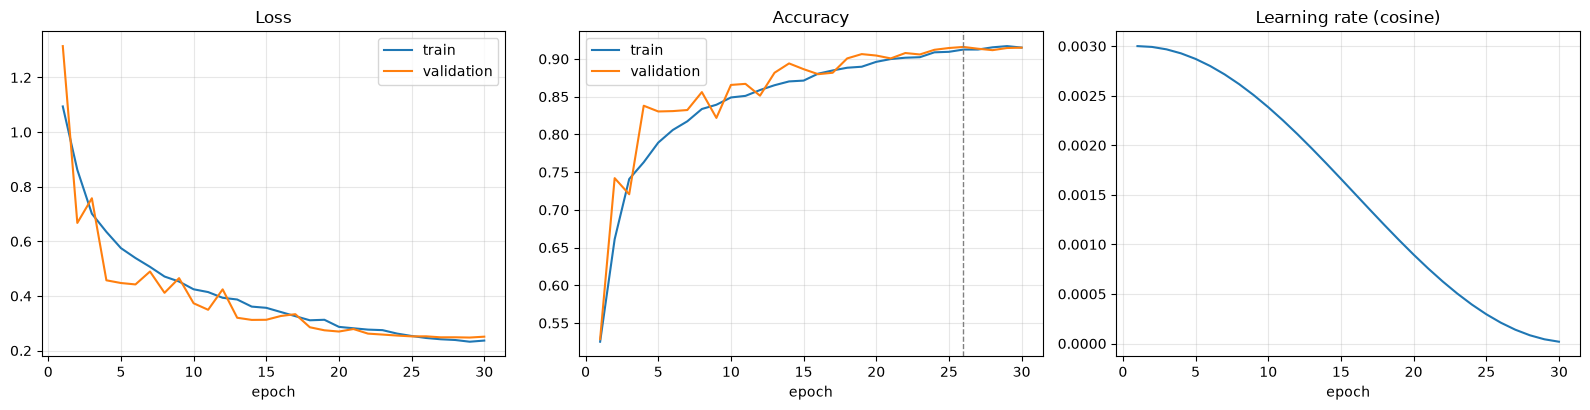

In [ ]:
with open(OUTPUTS_DIR / "history_scratch.json", encoding="utf-8") as f:
    saved = json.load(f)
hist = saved["history"]
epochs_axis = range(1, len(hist["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].plot(epochs_axis, hist["train_loss"], label="train")
axes[0].plot(epochs_axis, hist["val_loss"],   label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_axis, hist["train_acc"], label="train")
axes[1].plot(epochs_axis, hist["val_acc"],   label="validation")
axes[1].axvline(saved["best_epoch"], ls="--", c="gray", lw=1)
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(epochs_axis, hist["lr"])
axes[2].set_title("Learning rate (cosine)"); axes[2].set_xlabel("epoch"); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "curves_scratch.png", dpi=150, bbox_inches="tight")
plt.show()


ارزیابی روی مجموعه‌ی تست


In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

@torch.no_grad()
def predict_all(model, loader, device):
    """Return (labels, predictions, probabilities) for an entire loader."""
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            logits = model(xb)
        probs = torch.softmax(logits.float(), dim=1)
        all_labels.append(yb.numpy())
        all_preds.append(probs.argmax(1).cpu().numpy())
        all_probs.append(probs.cpu().numpy())
    return (np.concatenate(all_labels),
            np.concatenate(all_preds),
            np.concatenate(all_probs))


# Restore the best checkpoint (epoch 26), not the final-epoch weights
ckpt = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
eval_model = SceneCNN(num_classes=NUM_CLASSES).to(DEVICE)
eval_model.load_state_dict(ckpt["model_state"])
print(f"loaded checkpoint from epoch {ckpt['epoch']} (val acc {ckpt['val_acc']:.4f})")

y_true, y_pred, y_prob = predict_all(eval_model, test_loader, DEVICE)

test_acc      = accuracy_score(y_true, y_pred)
test_f1_macro = f1_score(y_true, y_pred, average="macro")

print(f"\ntest accuracy : {test_acc:.4f}")
print(f"test macro-F1 : {test_f1_macro:.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))


loaded checkpoint from epoch 26 (val acc 0.9159)

test accuracy : 0.9020
test macro-F1 : 0.9034

              precision    recall  f1-score   support

   buildings     0.9131    0.8902    0.9015       437
      forest     0.9709    0.9852    0.9780       474
     glacier     0.8805    0.8264    0.8526       553
    mountain     0.8485    0.8533    0.8509       525
         sea     0.8891    0.9588    0.9226       510
      street     0.9194    0.9102    0.9147       501

    accuracy                         0.9020      3000
   macro avg     0.9036    0.9040    0.9034      3000
weighted avg     0.9019    0.9020    0.9015      3000



ماتریس درهم‌ریختگی و ثبت نتایج


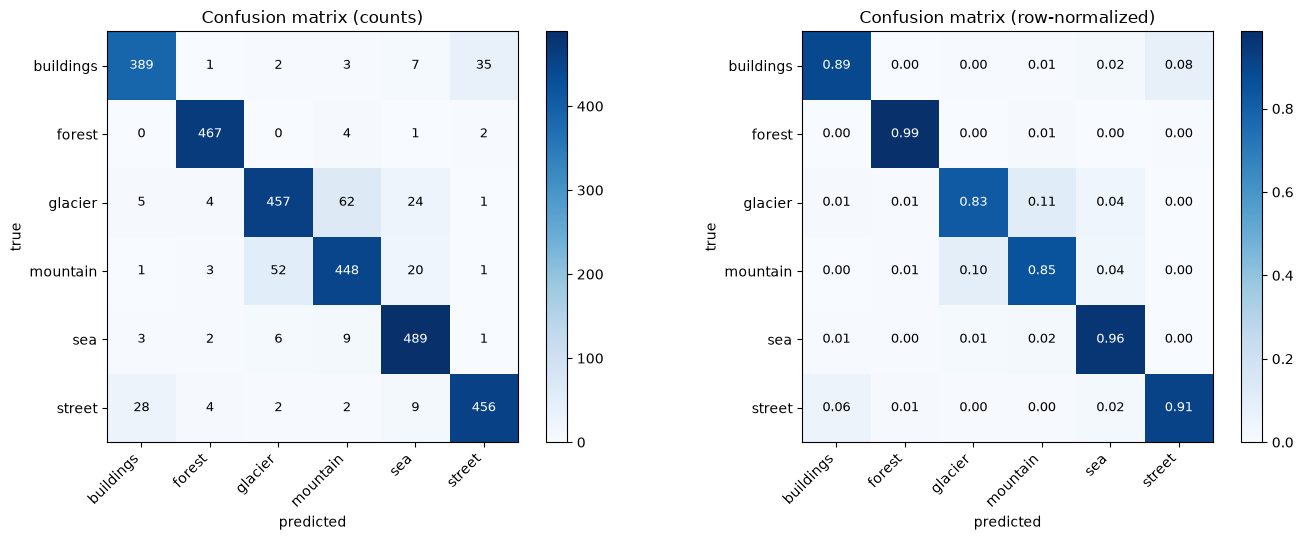


top confusions (true -> predicted):
  glacier      -> mountain     : 62
  mountain     -> glacier      : 52
  buildings    -> street       : 35
  street       -> buildings    : 28
  glacier      -> sea          : 24

saved: metrics_scratch.json, preds_scratch.npz


In [12]:
cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, mat, title, fmt in [
    (axes[0], cm,      "Confusion matrix (counts)",      "d"),
    (axes[1], cm_norm, "Confusion matrix (row-normalized)", ".2f"),
]:
    im = ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    thresh = mat.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, format(mat[i, j], fmt), ha="center", va="center",
                    color="white" if mat[i, j] > thresh else "black", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / "confusion_matrix_scratch.png", dpi=150, bbox_inches="tight")
plt.show()

# Most frequent confusions, useful for the written report
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]))
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
print("\ntop confusions (true -> predicted):")
for t, p, c in sorted(pairs, key=lambda x: -x[2])[:5]:
    print(f"  {t:12s} -> {p:12s} : {c}")

metrics = {
    "model": "SceneCNN (from scratch)",
    "params_total": int(sum(p.numel() for p in eval_model.parameters())),
    "best_epoch": int(ckpt["epoch"]),
    "val_acc": float(ckpt["val_acc"]),
    "test_acc": float(test_acc),
    "test_f1_macro": float(test_f1_macro),
    "per_class_recall": {CLASS_NAMES[i]: float(cm_norm[i, i]) for i in range(NUM_CLASSES)},
    "confusion_matrix": cm.tolist(),
    "train_time_min": 31.0,
}
with open(OUTPUTS_DIR / "metrics_scratch.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

np.savez_compressed(OUTPUTS_DIR / "preds_scratch.npz",
                    y_true=y_true, y_pred=y_pred, y_prob=y_prob)
print(f"\nsaved: metrics_scratch.json, preds_scratch.npz")
